<a href="https://colab.research.google.com/github/20danaai/Learn_LibrariesPy/blob/main/03_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import sklearn
from sklearn.datasets import make_circles

In [6]:
n_samples=1000
x,y=make_circles(n_samples,noise=0.05,random_state=42)

In [7]:
import pandas as pd
circles=pd.DataFrame({'x1':x[:,0],'x2':x[:,1],'label':y})
circles.head(10)

,x1,x2,label
0,0.742207,0.246686,1
1,-0.734032,0.168692,1
2,-0.829859,0.221959,1
3,-0.429136,0.672230,1
4,0.445602,-0.894936,0
5,-0.469885,0.708037,1
6,-0.016045,0.805623,1
7,0.759623,0.159526,1
8,-0.175692,-0.799837,1
9,-0.110616,1.042207,0


In [8]:
circles.label.value_counts()

,count
label,
1,500
0,500


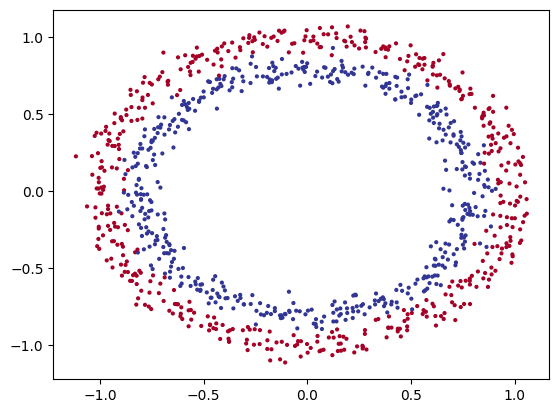

In [9]:

import matplotlib.pyplot as plt
plt.scatter(x=x[:,0],y=x[:,1],s=4,c=y,cmap=plt.cm.RdYlBu)


In [10]:
import torch
x=torch.from_numpy(x).type(torch.float)
y=torch.from_numpy(y).type(torch.float)

In [11]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [12]:
import torch
from torch import nn
device='cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [13]:
class circlemodel_v0(nn.Module):
  def __init__(self):
    super().__init__()
    self.layer1=nn.Linear(2,5)
    self.layer2=nn.Linear(5,1)
  def forward(self,x:torch.tensor)->torch.tensor:
    return self.layer2(self.layer1(x))


In [14]:
model_0=circlemodel_v0().to(device)
model_0

circlemodel_v0(
  (layer1): Linear(in_features=2, out_features=5, bias=True)
  (layer2): Linear(in_features=5, out_features=1, bias=True)
)

In [15]:
model_0=nn.Sequential(
    nn.Linear(2,5),
    nn.Linear(5,1)
)
model_0

Sequential(
  (0): Linear(in_features=2, out_features=5, bias=True)
  (1): Linear(in_features=5, out_features=1, bias=True)
)

In [16]:
loss_fn=nn.BCEWithLogitsLoss()
optimizier=torch.optim.SGD(params=model_0.parameters(),lr=0.01)

In [17]:
def accuracy_fun(y_true,y_pred):
  correct=torch.eq(y_pred,y_true).sum().item()
  acc=(correct/len(y_pred))*100
  return acc

In [18]:
x_true=torch.tensor([1,0,1,0,1,1])
x_pred=torch.tensor([1,0,1,1,1,1])
accuracy_fun(y_true=x_true,y_pred=x_pred)

83.33333333333334

In [19]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

In [20]:
x_train,y_train=x_train.to(device),y_train.to(device)
x_test,y_test=x_test.to(device),y_test.to(device)

In [21]:
epochs=30
device='cuda' if torch.cuda.is_available() else 'cpu'
model_0.to(device)
for epoch in range(epochs):
  model_0.train()
  y_logits=model_0(x_train).squeeze()
  y_pred=torch.round(torch.sigmoid(y_logits))
  print(y_logits.shape,y_train.shape)
  loss=loss_fn(y_logits,y_train)
  acc=accuracy_fun(y_true=y_train,y_pred=y_pred)
  optimizier.zero_grad()
  loss.backward()
  optimizier.step()
  model_0.eval()
  with torch.inference_mode():
    test_legist=model_0(x_test).squeeze()
    test_pred=torch.round(torch.sigmoid(test_legist))
    test_loss=loss_fn(test_legist,y_test)
    test_acc=accuracy_fun(y_true=y_test,y_pred=test_pred)
  if epochs %10==0:
    print(f'epoch : {epoch} | loss {loss:.5f} | Train Accuracy {acc:.5f} | Test loss : {test_loss:.5f} | Test acc :{test_acc:.5f}')


torch.Size([800]) torch.Size([800])
epoch : 0 | loss 0.74736 | Train Accuracy 50.00000 | Test loss : 0.73083 | Test acc :50.00000
torch.Size([800]) torch.Size([800])
epoch : 1 | loss 0.74692 | Train Accuracy 50.00000 | Test loss : 0.73045 | Test acc :50.00000
torch.Size([800]) torch.Size([800])
epoch : 2 | loss 0.74648 | Train Accuracy 50.00000 | Test loss : 0.73007 | Test acc :50.00000
torch.Size([800]) torch.Size([800])
epoch : 3 | loss 0.74605 | Train Accuracy 50.00000 | Test loss : 0.72970 | Test acc :50.00000
torch.Size([800]) torch.Size([800])
epoch : 4 | loss 0.74563 | Train Accuracy 50.00000 | Test loss : 0.72932 | Test acc :50.00000
torch.Size([800]) torch.Size([800])
epoch : 5 | loss 0.74521 | Train Accuracy 50.00000 | Test loss : 0.72896 | Test acc :50.00000
torch.Size([800]) torch.Size([800])
epoch : 6 | loss 0.74479 | Train Accuracy 50.00000 | Test loss : 0.72859 | Test acc :50.00000
torch.Size([800]) torch.Size([800])
epoch : 7 | loss 0.74438 | Train Accuracy 50.00000 | T

In [22]:
import requests
from pathlib import Path

In [23]:
utills_dire=Path('utills')
utills_dire.mkdir(parents=True,exist_ok=True)
if Path('helper_functions.py').is_file():
  print('helper_functions.py already exists, skipping download')
else:

  print("Downloading helper_functions.py")
  request=requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  with open (utills_dire/'helper_functions.py','wb') as f:
    f.write(request.content)
from utills.helper_functions import plot_predictions, plot_decision_boundary

In [24]:
import importlib
import utills.helper_functions as hf

importlib.reload(hf)

from utills.helper_functions import plot_predictions, plot_decision_boundary

In [25]:
print(hf.plot_predictions)
print(hf.plot_decision_boundary)

<function plot_predictions at 0x7ea8dca3d580>
<function plot_decision_boundary at 0x7ea8ea218180>


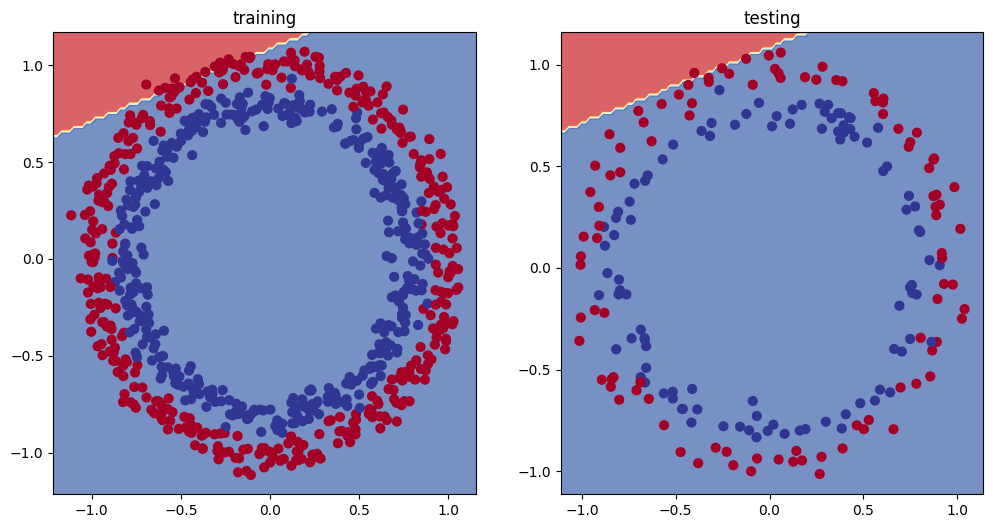

In [26]:
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title('training')
plot_decision_boundary(model_0,x_train,y_train)
plt.subplot(1,2,2)
plt.title('testing')
plot_decision_boundary(model_0,x_test,y_test)

In [31]:
class circlev2(nn.Module):
  def __init__(self):
    super().__init__()
    self.layer1=nn.Linear(2,10)
    self.layer2=nn.Linear(10,10)
    self.layer3=nn.Linear(10,1)
    self.relu=nn.ReLU()
  def forward(self,x: torch.tensor)-> torch.tensor:
    return self.relu(self.layer1(self.relu(self.layer2(self.relu(self.layer1(x))))))
model_1=circlev2().to(device)





In [32]:
loss=nn.BCEWithLogitsLoss()
optimizier=torch.optim.SGD(params=model_1.parameters(),lr=0.01)